# Tugas Laboratorium JS07: Klasterisasi Data Nasabah Kartu Kredit

Dataset berisi 660 nasabah dengan lima variabel yang bisa dipakai untuk klasterisasi: `Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, dan `Total_calls_made`. Kolom `Sl_No` cuma nomor urut dan `Customer Key` adalah identitas, jadi keduanya tidak dipakai.

Semua langkah memakai `random_state=42` supaya hasilnya bisa diulang, dan fitur diskalakan lebih dulu karena `Avg_Credit_Limit` punya skala ribuan sementara jumlah kunjungan dan panggilan cuma satuan.


## 1. Import Library


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


## 2. Load dan Inspeksi Data


In [2]:
df = pd.read_csv('dataset/Credit_Card_Customer_Data.csv')
df.head()


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
print(df.shape)
df.info()


(660, 7)
<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [4]:
df.describe().T[['mean', 'std', 'min', '50%', 'max']]


,mean,std,min,50%,max
Sl_No,330.500000,190.669872,1.0,330.5,660.0
Customer Key,55141.443939,25627.772200,11265.0,53874.5,99843.0
Avg_Credit_Limit,34574.242424,37625.487804,3000.0,18000.0,200000.0
Total_Credit_Cards,4.706061,2.167835,1.0,5.0,10.0
Total_visits_bank,2.403030,1.631813,0.0,2.0,5.0
Total_visits_online,2.606061,2.935724,0.0,2.0,15.0
Total_calls_made,3.583333,2.865317,0.0,3.0,10.0


In [5]:
print('Missing values:', df.isna().sum().sum())
print('Baris duplikat (persis):', df.duplicated().sum())
print('Duplikat pada 5 fitur klasterisasi:', df.duplicated(subset=df.columns[2:]).sum())


Missing values: 0
Baris duplikat (persis): 0
Duplikat pada 5 fitur klasterisasi: 11


660 baris, tanpa nilai kosong, dan tipe datanya bilangan bulat semua. Ada 11 baris yang isinya sama kalau dibandingkan hanya pada lima fiturnya, wajar karena `Avg_Credit_Limit` dan `Total_Credit_Cards` banyak yang bernilai sama antar nasabah. Barisnya tetap dipakai karena yang berbeda adalah nasabahnya, bukan datanya.


## 3. Soal 1 - Scatterplot `Avg_Credit_Limit` vs `Total_Credit_Cards`


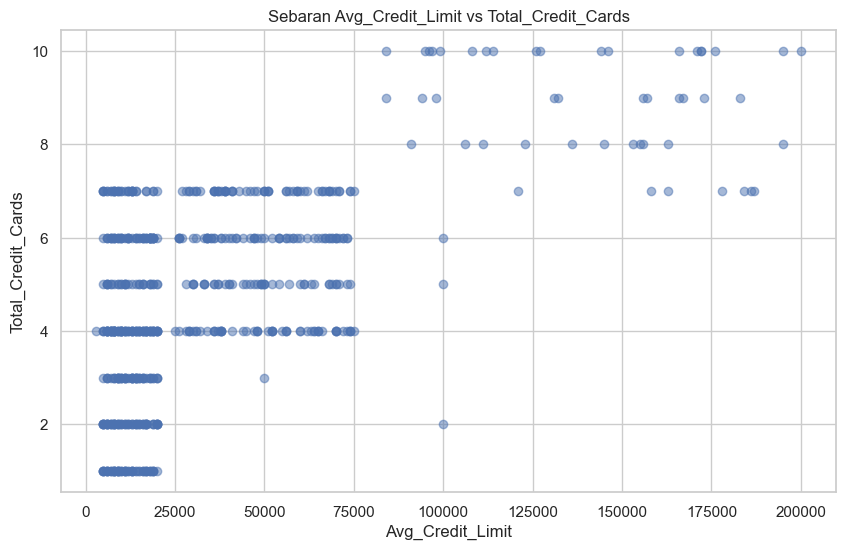

In [6]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], alpha=0.5)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()


In [7]:
print('Korelasi Pearson:', df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards']))


Korelasi Pearson: 0.6088604935524962


**Jawaban soal 1: sebarannya tidak linear.**

Titik-titiknya mengumpul di beberapa kolom vertikal, karena `Total_Credit_Cards` hanya bernilai bulat 1 sampai 10, sementara `Avg_Credit_Limit` menyebar di rentang yang lebar. Pola yang terlihat bukan garis lurus, melainkan tangga: limit yang lebih tinggi cenderung diikuti jumlah kartu yang lebih banyak, tapi sebarannya menggerombol di tiap tingkat.

Korelasinya sekitar 0.61, cukup kuat tapi bukan hubungan linear yang rapi. Bentuk seperti ini juga berarti K-Means berpotensi kesulitan, karena batas clusternya selalu linear.


## 4. Preprocessing

Lima fitur klasterisasi distandarkan supaya tidak ada satu variabel yang mendominasi jarak.


In [8]:
fitur = df.columns[2:]
X = df[fitur].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=fitur).describe().T[['mean', 'std', 'min', 'max']]


,mean,std,min,max
Avg_Credit_Limit,8.612639e-17,1.000758,-0.839808,4.399975
Total_Credit_Cards,4.306320e-17,1.000758,-1.710864,2.443892
Total_visits_bank,-4.306320e-17,1.000758,-1.473731,1.592670
Total_visits_online,7.536059e-17,1.000758,-0.888380,4.224968
Total_calls_made,-8.612639e-17,1.000758,-1.251537,2.241125


## 5. Soal 2 - Menentukan `k` Terbaik dengan Elbow Method


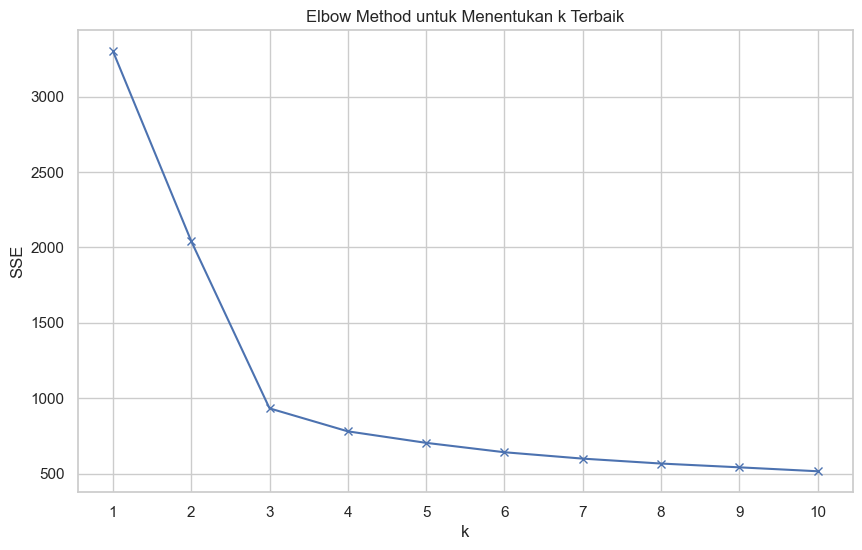

In [9]:
sse = []
K = range(1, 11)

for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    sse.append(model.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(K, sse, 'bx-')
plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Elbow Method untuk Menentukan k Terbaik')
plt.xticks(list(K))
plt.show()


In [10]:
for k, nilai in zip(K, sse):
    print(f'k={k}: SSE={nilai:.2f}')


k=1: SSE=3300.00
k=2: SSE=2040.99
k=3: SSE=933.04
k=4: SSE=780.77
k=5: SSE=704.48
k=6: SSE=642.27
k=7: SSE=599.93
k=8: SSE=567.33
k=9: SSE=542.25
k=10: SSE=516.24


**Jawaban soal 2: `k=3`.**

Penurunan SSE dari `k=1` ke `k=2` dan dari `k=2` ke `k=3` sangat besar, lalu setelah `k=3` garisnya melandai dan penurunannya makin kecil per tambahan cluster. Titik elbow-nya ada di `k=3`, jadi angka itu yang dipilih.

Alasannya juga masuk akal secara bisnis. Tiga cluster memisahkan nasabah bernilai rendah, menengah, dan tinggi, yang masing-masing punya pola interaksi berbeda. Menambah cluster keempat hanya memecah kelompok yang sudah cukup homogen.


## 6. Soal 3 - Hasil Klasterisasi K-Means


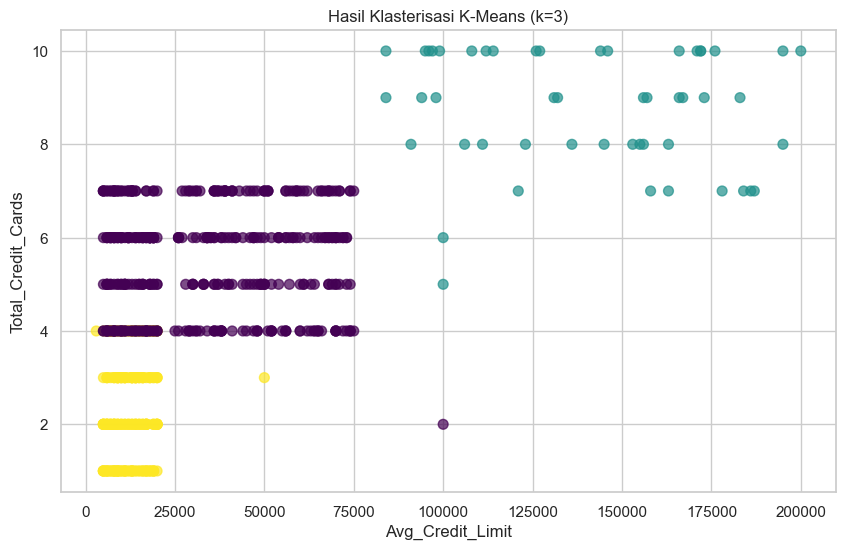

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
label_kmeans = kmeans.fit_predict(X_scaled)

df['cluster_kmeans'] = label_kmeans

plt.figure(figsize=(10, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'],
            c=label_kmeans, s=50, cmap='viridis', alpha=0.7)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.show()


In [12]:
profil = df.groupby('cluster_kmeans')[list(fitur)].mean().round(1)
profil['jumlah_nasabah'] = df['cluster_kmeans'].value_counts().sort_index()
profil


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah_nasabah
cluster_kmeans,,,,,,
0,33782.4,5.5,3.5,1.0,2.0,386
1,141040.0,8.7,0.6,10.9,1.1,50
2,12174.1,2.4,0.9,3.6,6.9,224


In [13]:
print(f'Silhouette Score (K-Means): {silhouette_score(X_scaled, label_kmeans):.4f}')
print(f'Davies-Bouldin Index (K-Means): {davies_bouldin_score(X_scaled, label_kmeans):.4f}')


Silhouette Score (K-Means): 0.5157
Davies-Bouldin Index (K-Means): 0.6797


Ketiga cluster terpisah jelas kalau dilihat dari profil rata-ratanya: satu kelompok limit rendah dengan panggilan banyak, satu kelompok menengah yang rajin ke bank, dan satu kelompok limit tinggi yang aktif online.


## 7. Soal 4 - Klasterisasi dengan DBSCAN

DBSCAN butuh nilai `eps` yang sesuai dengan skala data. Karena fitur sudah distandarkan, jarak antar tetangga bisa dibaca dari grafik k-distance lalu dicari titik lengkungnya.


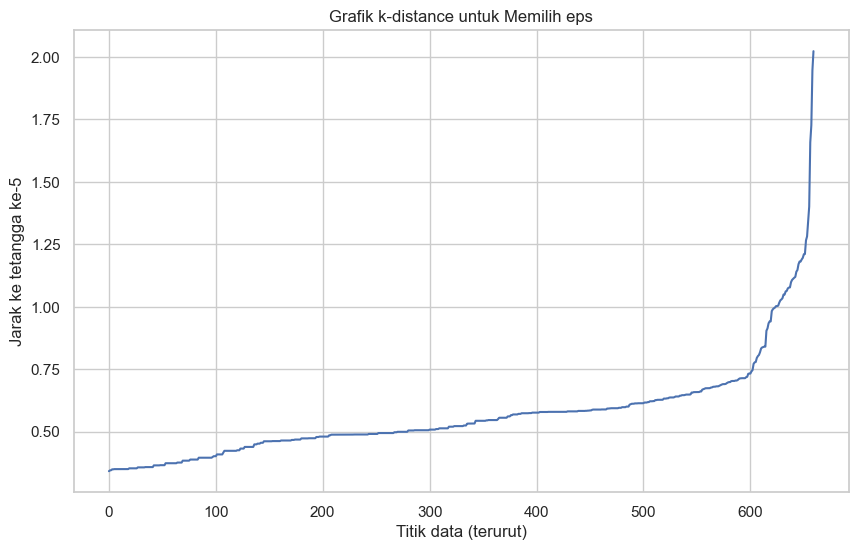

In [14]:
tetangga = NearestNeighbors(n_neighbors=5).fit(X_scaled)
jarak, _ = tetangga.kneighbors(X_scaled)
jarak = np.sort(jarak[:, -1])

plt.figure(figsize=(10, 6))
plt.plot(jarak)
plt.xlabel('Titik data (terurut)')
plt.ylabel('Jarak ke tetangga ke-5')
plt.title('Grafik k-distance untuk Memilih eps')
plt.show()


In [15]:
# Titik lengkung dicari dari jarak terjauh ke garis penghubung ujung-ujung kurva
x = np.arange(len(jarak))
x1, y1, x2, y2 = x[0], jarak[0], x[-1], jarak[-1]
jarak_ke_garis = np.abs((y2 - y1) * x - (x2 - x1) * jarak + x2 * y1 - y2 * x1)
jarak_ke_garis /= np.hypot(y2 - y1, x2 - x1)

knee = int(np.argmax(jarak_ke_garis))
print(f'Titik lengkung di data ke-{knee} (persentil {knee / len(jarak) * 100:.1f}%)')
print(f'eps saran: {jarak[knee]:.3f}')


Titik lengkung di data ke-595 (persentil 90.2%)
eps saran: 0.714


Lengkungnya jatuh di sekitar persentil ke-90 dengan `eps` sekitar 0.71. Rentang yang masuk akal jadi sekitar 0.7 sampai 1.0, dan itu yang dicoba satu per satu.


In [16]:
for eps in [0.7, 0.8, 0.9, 1.0, 1.2]:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_scaled)
    n_cluster = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    noise = (db.labels_ == -1).sum()
    print(f'eps={eps}: {n_cluster} cluster, {noise} noise ({noise / len(db.labels_) * 100:.1f}%)')


eps=0.7: 1 cluster, 58 noise (8.8%)
eps=0.8: 2 cluster, 44 noise (6.7%)
eps=0.9: 3 cluster, 27 noise (4.1%)
eps=1.0: 2 cluster, 18 noise (2.7%)
eps=1.2: 2 cluster, 4 noise (0.6%)


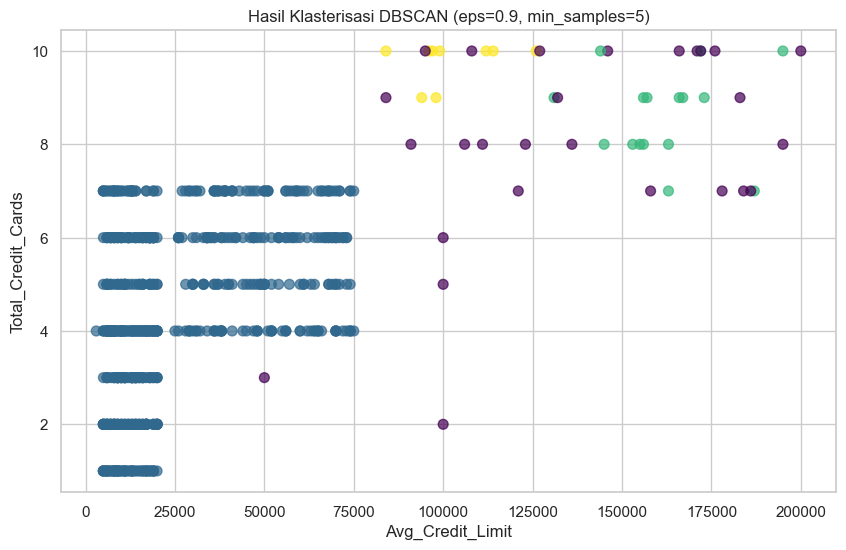

In [17]:
dbscan = DBSCAN(eps=0.9, min_samples=5)
label_dbscan = dbscan.fit_predict(X_scaled)

df['cluster_dbscan'] = label_dbscan

plt.figure(figsize=(10, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'],
            c=label_dbscan, s=50, cmap='viridis', alpha=0.7)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi DBSCAN (eps=0.9, min_samples=5)')
plt.show()


In [18]:
ringkasan_dbscan = df.groupby('cluster_dbscan')[list(fitur)].mean().round(1)
ringkasan_dbscan['jumlah_nasabah'] = df['cluster_dbscan'].value_counts().sort_index()
ringkasan_dbscan


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah_nasabah
cluster_dbscan,,,,,,
-1,137000.0,8.0,0.4,11.7,1.2,27
0,25685.9,4.4,2.6,1.9,3.8,608
1,161437.5,8.6,0.8,9.7,1.2,16
2,102222.2,9.8,0.9,9.4,1.2,9


In [19]:
jumlah_cluster_db = len(set(label_dbscan)) - (1 if -1 in label_dbscan else 0)
noise_db = (label_dbscan == -1).sum()

print(f'Jumlah cluster: {jumlah_cluster_db}')
print(f'Titik noise: {noise_db} dari {len(label_dbscan)} ({noise_db / len(label_dbscan) * 100:.1f}%)')


Jumlah cluster: 3
Titik noise: 27 dari 660 (4.1%)


DBSCAN menemukan tiga cluster inti plus 27 titik yang ditandai noise. Ini beda dengan K-Means yang memaksa semua titik masuk cluster.

Dua cluster intinya kecil, berisi nasabah dengan limit tinggi dan kartu banyak, sementara satu cluster besar menampung 608 nasabah sisanya. Yang menarik, noise-nya justru nasabah limit tinggi juga: mereka punya nilai ekstrem di beberapa fitur sekaligus sehingga tidak cukup rapat untuk bergabung ke cluster mana pun. DBSCAN tidak memerlukan jumlah cluster ditentukan di awal, jadi kelompok yang muncul adalah hasil dari kerapatan data.


## 8. Soal 5 - Elbow Method untuk DBSCAN

DBSCAN tidak menghasilkan SSE, jadi elbow method tidak bisa langsung dipakai. Padanan terdekatnya adalah mencari nilai `eps` terbaik, dan itu dilakukan dengan memplot jumlah cluster dan persentase noise pada beberapa nilai `eps`.


In [20]:
eps_list = np.arange(0.3, 2.01, 0.1)
hasil = []

for eps in eps_list:
    db = DBSCAN(eps=eps, min_samples=5).fit(X_scaled)
    n_cluster = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    noise = (db.labels_ == -1).sum() / len(db.labels_) * 100
    hasil.append((eps, n_cluster, noise))

hasil_df = pd.DataFrame(hasil, columns=['eps', 'jumlah_cluster', 'persen_noise'])
hasil_df.round(2)


,eps,jumlah_cluster,persen_noise
0,0.3,0,100.00
1,0.4,25,72.27
2,0.5,24,31.06
3,0.6,8,12.42
4,0.7,1,8.79
5,0.8,2,6.67
6,0.9,3,4.09
7,1.0,2,2.73
8,1.1,2,0.91
9,1.2,2,0.61


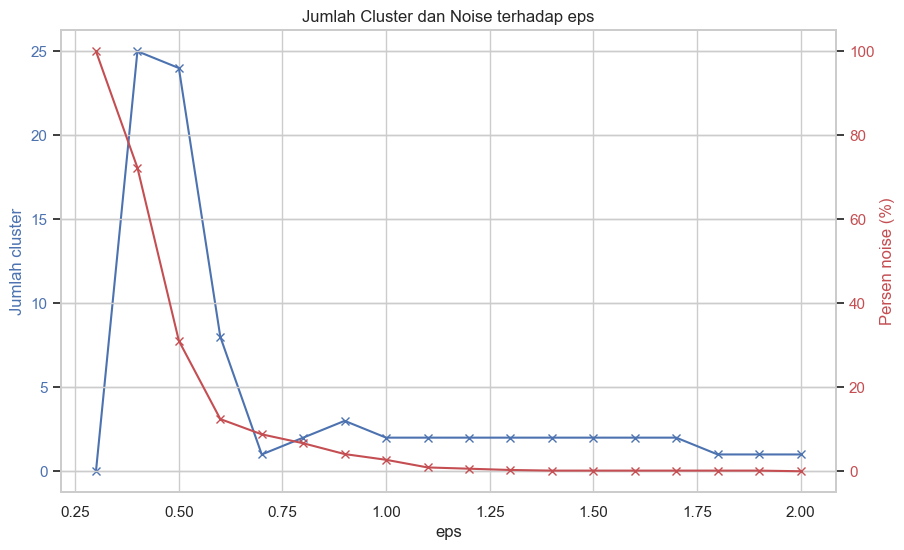

In [21]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(hasil_df['eps'], hasil_df['jumlah_cluster'], 'bx-', label='Jumlah cluster')
ax1.set_xlabel('eps')
ax1.set_ylabel('Jumlah cluster', color='b')
ax1.tick_params(axis='y', labelcolor='b')

ax2 = ax1.twinx()
ax2.plot(hasil_df['eps'], hasil_df['persen_noise'], 'rx-', label='Persen noise')
ax2.set_ylabel('Persen noise (%)', color='r')
ax2.tick_params(axis='y', labelcolor='r')

plt.title('Jumlah Cluster dan Noise terhadap eps')
plt.show()


**Jawaban soal 5.**

SSE tidak tersedia di DBSCAN, jadi pertanyaan `k` terbaik dijawab lewat dua cara. Untuk K-Means, elbow method menunjuk `k=3` seperti pada soal 2. Untuk DBSCAN, nilai `eps` terbaik dicari lewat grafik di atas, karena `eps` berperan seperti penentu seberapa besar cluster yang terbentuk.

Pola pada grafiknya: di bawah `eps=0.6` noise melonjak karena radiusnya terlalu kecil untuk menjangkau tetangga. Mulai `eps=1.0` ke atas, cluster menyatu jadi dua saja dan setelah `eps=1.8` semuanya melebur menjadi satu cluster. Daerah yang seimbang ada di `eps=0.8` sampai `0.9`, tempat jumlah cluster stabil di 2 sampai 3 dan noise-nya masih di bawah 7 persen. Nilai `eps=0.9` yang dipakai karena memberi cluster terbanyak tanpa mengorbankan banyak titik sebagai noise.

Kalau tetap ingin angka `k` untuk DBSCAN, jawabannya tiga cluster inti, sama seperti hasil elbow method pada K-Means.


## 9. Soal 6 - Silhouette Score dan DBI untuk DBSCAN

Silhouette dan DBI tidak bisa menghitung label noise, jadi titik berlabel `-1` dikeluarkan dulu.


In [22]:
mask = label_dbscan != -1
X_db = X_scaled[mask]
label_db_bersih = label_dbscan[mask]

print(f'Jumlah cluster (tanpa noise): {len(set(label_db_bersih))}')
print(f'Silhouette Score (DBSCAN): {silhouette_score(X_db, label_db_bersih):.4f}')
print(f'Davies-Bouldin Index (DBSCAN): {davies_bouldin_score(X_db, label_db_bersih):.4f}')


Jumlah cluster (tanpa noise): 3
Silhouette Score (DBSCAN): 0.4940
Davies-Bouldin Index (DBSCAN): 0.8784


In [23]:
perbandingan = pd.DataFrame({
    'Model': ['K-Means (k=3)', 'DBSCAN (eps=0.9, min_samples=5)'],
    'Jumlah cluster': [len(set(label_kmeans)), len(set(label_db_bersih))],
    'Silhouette': [silhouette_score(X_scaled, label_kmeans),
                   silhouette_score(X_db, label_db_bersih)],
    'Davies-Bouldin': [davies_bouldin_score(X_scaled, label_kmeans),
                       davies_bouldin_score(X_db, label_db_bersih)],
})
perbandingan.round(4)


,Model,Jumlah cluster,Silhouette,Davies-Bouldin
0,K-Means (k=3),3,0.5157,0.6797
1,"DBSCAN (eps=0.9, min_samples=5)",3,0.4940,0.8784


**Jawaban soal 6.** Nilai lengkapnya ada di tabel perbandingan di atas. DBSCAN mendapat silhouette 0.4940 dan DBI 0.8784, sedikit lebih buruk dari K-Means yang dapat 0.5157 dan 0.6797. Ada dua catatan soal cara membacanya:

- Silhouette dan DBI dihitung tanpa titik noise, jadi DBSCAN dinilai dari data yang benar-benar masuk cluster. Ini membuat perbandingan dengan K-Means tidak sepenuhnya setara, karena K-Means dinilai pada seluruh 660 titik.
- DBI yang lebih kecil lebih baik, sedangkan silhouette yang lebih besar lebih baik. K-Means unggul di kedua metrik, tapi itu bukan berarti hasilnya lebih benar. Metrik ini mengukur kepadatan dan separasi berbentuk bulat, sesuatu yang memang jadi kekuatan K-Means. DBSCAN sengaja membiarkan titik ekstrem di luar cluster, dan justru titik-titik itu yang membuatnya menarik untuk ditinjau.


## 10. Kesimpulan

Elbow method menunjuk `k=3` untuk K-Means, dan profil ketiga cluster itu masuk akal: nasabah limit menengah yang rajin ke bank (386 nasabah), nasabah limit rendah dengan panggilan banyak (224 nasabah), dan nasabah limit tinggi yang aktif online (50 nasabah).

DBSCAN menghasilkan tiga cluster inti juga, tapi dengan komposisi yang jauh berbeda: satu cluster besar berisi 608 nasabah dan dua cluster kecil berisi nasabah limit tinggi. Sebanyak 27 nasabah ditandai sebagai noise, dan mereka semua juga berlimit tinggi. Keunggulan DBSCAN, jumlah cluster tidak perlu ditentukan di awal dan bentuknya tidak dipaksa bulat. Kelemahannya, hasilnya sangat bergantung pada `eps` dan `min_samples`, dan penentuan parameternya tidak segampang membaca elbow.

Untuk data nasabah ini, K-Means lebih praktis karena jumlah segmennya memang ingin ditentukan untuk keperluan segmentasi. DBSCAN lebih cocok dipakai sebagai pemeriksaan tambahan, terutama untuk menemukan nasabah dengan perilaku menyimpang yang layak ditinjau terpisah.
